# Classification de textes – détecteur de spams

Nous commençons par charger tous les paquets et fonctions auxiliaires nécessaires.

In [1]:
# Load packages and helper functions
%run data_prep_tools.py
%run EDA_tools.py
%run modeling_tools.py

## Création d'un détecteur de spams

### Objectif

Nous souhaitons concevoir un détecteur de spams qui, à partir d'exemples d'e-mails indésirables (par exemple, signalés par des utilisateurs) et d'e-mails légitimes (non-spams, aussi appelés « ham »), apprend à classer de nouveaux e-mails — jamais rencontrés auparavant — comme étant des spams ou non.

### Données

Dans les notebooks précédents, nous avons abordé les étapes suivantes :
* Chargement des données
* Prétraitement du texte
* Extraction de caractéristiques (features)
* Exploration des données

Nous avons également créé différents ensembles de caractéristiques.

Ces ensembles peuvent être chargés à l'aide de la fonction `load_feature_space()`. Les options disponibles sont :
* "num" : caractéristiques numériques
* "text" : caractéristiques textuelles
* "num_text" : combinaison de caractéristiques numériques et textuelles
* "embedding" : caractéristiques issues de plongements (embeddings)

### Dans ce notebook

Notre objectif est de construire un détecteur de spams simple. Nous commencerons par explorer les différents jeux de données, puis nous concevrons un détecteur de spams et évaluerons ses performances. La démarche suivra ces étapes :
* Chargement des caractéristiques
* Division des données en ensembles d'entraînement et de test
* Entraînement d'un détecteur de spams simple
* Évaluation du modèle
* Analyse des exemples mal classés

## Chargement des données

In [2]:
# Load the data sets
num_features_df = load_feature_space("num", no_labels=False)
text_features_df = load_feature_space("text", no_labels=False)
num_text_features_df = load_feature_space("num_text", no_labels=False)
embedding_features = load_feature_space("embedding", no_labels=False)
labels = load_labels()

Numeric features loaded
Data includes labels in the column 'spam_label'
The data set has 5832 rows, 14 columns
Text features loaded
Data includes labels in the column 'spam_label'
The data set has 5832 rows, 8219 columns
Numeric and text features loaded
Data includes labels in the column 'spam_label'
The data set has 5832 rows, 8232 columns
Email embeddings loaded
Data includes labels in the column 'spam_label'
The data set has 5832 rows, 769 columns
5832 labels loaded
Labels found: [1 0]


## Une référence de base

Imaginons que vous appliquiez une **approche très naïve** au problème de la détection des spams, **qui n'utilise aucune caractéristique (variable)** :

**Référence de base : _Classer tous les e-mails soit comme « spam », soit comme « non-spam »._**

Cette approche naïve est utile pour établir une **référence de base** (ou *baseline*) permettant d'évaluer la performance de nos classifieurs plus complexes.
Dans ce notebook, nous allons concevoir différents détecteurs de spams et comparer leurs performances à cette référence.

Vérifions le nombre d'échantillons par classe dans les données.

Samples per class (%):
non-spam    70.3
spam        29.7
Name: proportion, dtype: float64




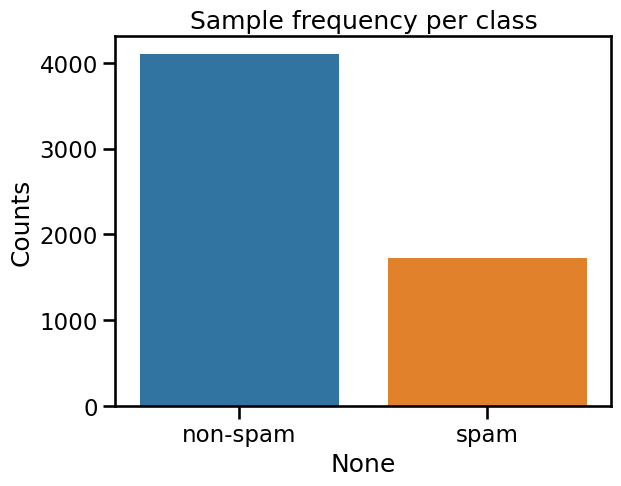

In [3]:
plot_class_frequency(labels)

<div class="alert alert-success">


<h3>Questions</h3>

__Q1.__ Combien d’e-mails seraient correctement classés dans chaque cas ?

__Q2.__ Quelle approche serait la plus efficace ?

</div>

#### Indiquez vos observations ici :

**Q1**

- Prédiction systématique de « non-spam » : les 70,3 % de messages légitimes sont correctement identifiés, tandis que la totalité des 29,7 % de spams sont manqués ; précision : 70,3 %.
- Prédiction systématique de « spam » : les 29,7 % de spams sont correctement identifiés, mais les 70,3 % de messages légitimes sont classés à tort comme spams ; précision : 29,7 %.




**Q2**

- La première approche (prédire systématiquement « non-spam ») offre la meilleure précision : 70,3 %.
- Elle serait toutefois inutile pour un détecteur de spams, puisqu'elle ne parviendrait à en identifier aucun.
- Les algorithmes d'apprentissage automatique ne connaissent pas les implications concrètes de chaque scénario. Par conséquent, si les modèles ne parviennent pas à dégager des tendances statistiquement pertinentes, ils pourraient « se contenter » de cette première approche, bien qu'elle soit sans aucune utilité pour nous.
- Il existe un risque réel que le modèle opte pour cette stratégie sans avoir rien appris d'utile. C'est pourquoi tous nos modèles doivent faire mieux que cette approche naïve ; nous l'utilisons donc comme référence (ou « baseline »).

# Construction du modèle

Nous sommes désormais prêts à construire notre modèle d'apprentissage automatique destiné à la détection des spams.

Tout au long de ce notebook, nous utiliserons un classifieur par **régression logistique** (un classifieur linéaire). Voici pourquoi :
- Il s'agit d'un modèle simple et efficace pour les tâches de classification binaire.
- Il constitue une excellente base de référence (*baseline*) pour des modèles plus complexes.
- Il est rapide à entraîner, ce qui permet d'itérer rapidement sur le modèle et de tester différents paramètres.
- Il est également facile à interpréter, ce qui nous permet d'analyser les situations dans lesquelles le modèle commet des erreurs.

Dans la suite, vous allez :
- construire un premier modèle simple ;
- ajuster le principal hyperparamètre, `C`, à l'aide d'une recherche sur grille (*grid search*) avec validation croisée (cross-validation);
- explorer différents ensembles de variables explicatives (*features*) et observer leur impact sur les performances du modèle ;
- examiner l'effet de différentes métriques d'évaluation ;
- analyser les échantillons mal classés.

### Un premier essai

À titre de premier essai, nous utiliserons l’ensemble de caractéristiques `num` avec un modèle de régression logistique simple.

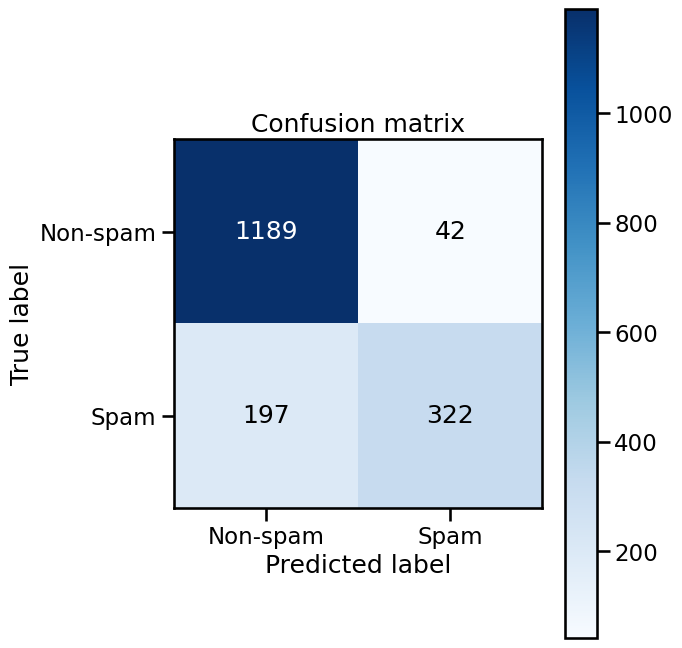

In [4]:
# Train/test splitting
df_train, df_test = train_test_split_(num_features_df)

# Fit model on the train data
model = fit_model(df_train, C=1)

# Print predictions on test set
plot_confusion_matrix(df_test, model)

<div class="alert alert-success">


<h3>Questions</h3>

Examinons la grille ci-dessus.

__Q1.__ Quels nombres indiquent les prédictions correctes pour chaque classe ?

__Q2.__ Quels nombres indiquent les prédictions erronées pour chaque classe ?

__Q3.__ Quelle classe a obtenu les meilleurs résultats ?


</div>

#### Indiquez vos observations ici :

**Q1**

- La case en haut à gauche indique les e-mails qui ne sont pas des spams et qui ont été correctement identifiés comme tels.
- La case en bas à droite indique les e-mails qui sont des spams et qui ont été correctement identifiés comme tels.


**Q2**

- La case en haut à droite indique le nombre d'e-mails qui ne sont pas des spams, mais qui ont été classés à tort comme spams.
- La case en bas à gauche indique les e-mails qui sont des spams, mais que le modèle n'a pas réussi à détecter.


**Q3**

- Cette question est ambiguë, car nous n'avons pas défini ce que nous entendons par « meilleur ». Meilleur par rapport à quoi ?
- Si l'on se réfère aux étiquettes réelles (rappel), le modèle affiche une performance nettement supérieure pour les e-mails qui ne sont pas des spams : il y a très peu d'erreurs de classification, alors qu'environ un tiers des spams n'ont pas été détectés.
- Si l'on examine la proportion de prédictions qui correspondent à la classe réelle (précision), on constate que les e-mails classés comme spams présentent une performance légèrement meilleure que ceux classés comme e-mails normaux. Pour un utilisateur qui ne connaît pas la classe réelle, cela signifie qu'il convient d'accorder un peu moins de confiance aux prédictions indiquant qu'un e-mail n'est pas un spam.

### Évaluation d'un modèle à l'aide de différentes métriques

Le rapport de classification fournit quatre métriques permettant d'évaluer les performances de notre modèle : trois métriques pour chaque classe, ainsi que la précision globale (accuracy).

La **exactitude** (*accuracy*) correspond au nombre de prédictions correctes divisé par le nombre total d'échantillons. Il s'agit donc de la proportion d'éléments correctement classés situés sur la diagonale.

La **précision** (*precision*) d'une classe correspond à la proportion de prédictions correctes parmi tous les échantillons que le modèle a attribués à cette classe ; on examine ici les proportions au sein d'une colonne.

Le **rappel** (*recall* ou *sensibilité*), d'une classe correspond à la proportion d'échantillons appartenant à cette classe qui ont été correctement identifiés par le modèle ; on examine ici les proportions au sein d'une ligne.

La **F-mesure** (*F1-score*) est la moyenne harmonique de la précision et du rappel.

In [5]:
# Print classification report for test set
classification_report_(df_test, model)

              precision    recall  f1-score   support

    Non-spam       0.86      0.97      0.91      1231
        Spam       0.88      0.62      0.73       519

    accuracy                           0.86      1750
   macro avg       0.87      0.79      0.82      1750
weighted avg       0.87      0.86      0.86      1750



Vous pourriez envisager de modifier le paramètre `C` dans la fonction `fit_model` pour observer son incidence sur les performances du modèle. Toutefois, cette pratique est déconseillée, car elle revient à ajuster le modèle en fonction de l'ensemble de test, lequel est par ailleurs utilisé pour l'évaluation.

Privilégions plutôt une approche plus appropriée, présentée ci-dessous.

### Une approche plus systématique du réglage fin

Nous utiliserons une validation croisée à 5 plis (5-fold cross-validation). Les ensembles de validation sont ainsi créés automatiquement en interne. L'ensemble de test servira à `évaluer` les performances de notre modèle. Le processus sélectionnera automatiquement le meilleur modèle pour nous. Nous conservons également tous les résultats issus de la validation croisée afin de pouvoir les représenter graphiquement ci-dessous.

In [6]:
%%time

# Train/test splitting
df_train, df_test = train_test_split_(num_features_df)
# Warning text_features_df or num_text_features_df can take longer to run the full 5-fold cross-validation

# Fit model on the train data
# For text features set `scaler=False`
model, cv_results = fit_log_reg_model(df_train, scoring=None, scaler=True)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
CPU times: user 167 ms, sys: 128 ms, total: 296 ms
Wall time: 3.95 s


#### Suivi du surapprentissage

Nous représentons ci-dessous les résultats de la validation croisée. L'axe des abscisses indique les différentes valeurs de `C` testées, tandis que l'axe des ordonnées affiche la métrique du modèle, évaluée sur l'ensemble d'entraînement (en bleu) et sur l'ensemble de validation (en orange). La croix rouge indique la valeur de `C` optimale obtenue.

Nous nous intéressons à l'écart entre les courbes correspondant à l'ensemble d'entraînement et à l'ensemble de validation. Si cet écart est faible, cela signifie que notre modèle ne présente pas de surapprentissage et qu'il généralise bien à des données inédites. Si, en revanche, l'écart est important, cela indique que le modèle est en situation de **surapprentissage** (*overfitting*). Cela signifie qu'il a appris des informations non pertinentes — comme du « bruit » — qui ne reflètent pas la tendance générale. Dans ce cas, il est nécessaire d'ajuster le modèle afin de réduire cet écart et d'améliorer ses performances sur l'ensemble de validation.

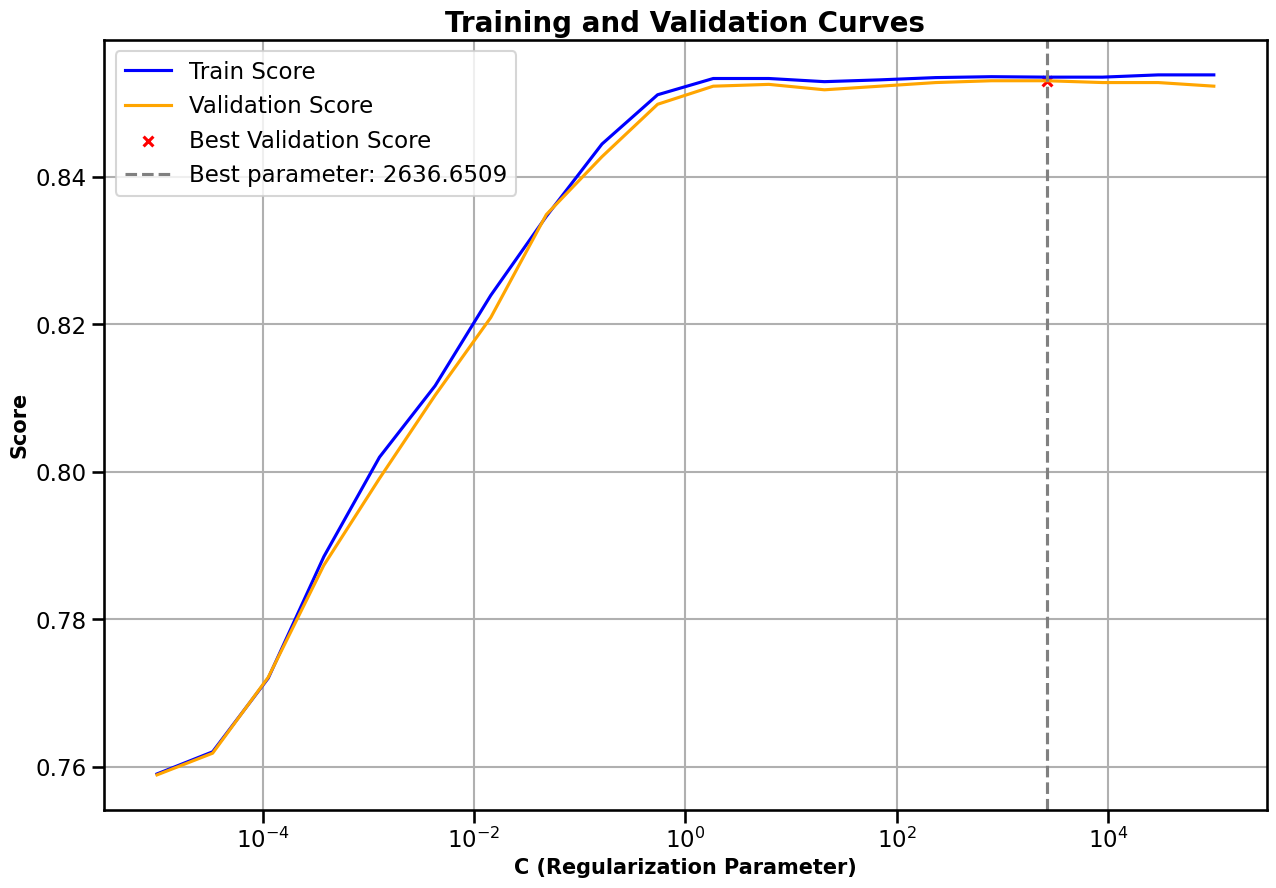

In [7]:
viz_cv_results(cv_results, show_table=False, plot_confidence=False, plot_fit_time=False)

<div class="alert alert-success">


<h3>Questions</h3>

Analysons le graphique ci-dessus.

__Q1.__ Observe-t-on un surapprentissage (overfitting), c'est-à-dire un écart important entre les courbes d'entraînement et de validation ?

__Q2.__ Que se passe-t-il lorsque C est très petit, et lorsqu'il est très grand ?


</div>

#### Indiquez vos observations ici :

**Q1**

- Non, les scores d'entraînement et les scores de validation sont très proches les uns des autres pour toutes les valeurs de l'hyperparamètre `C`. Par conséquent, les modèles ne présentent pas de surapprentissage (overfitting) et généralisent bien ; ils obtiennent des performances similaires sur les données de validation, qui n'ont pas été utilisées lors de l'entraînement.


**Q2**

- Lorsque `C` devient très petit, les deux scores de précision diminuent et se rapprochent de la précision du modèle de référence (baseline).
- Remarque : des valeurs de `C` faibles impliquent une pénalité importante pour le modèle. On constate que cela nuit au processus d'apprentissage ; en quelque sorte, nous « tuons » le modèle par notre intervention.
- Lorsque `C` devient très grand, les deux scores de précision se stabilisent à un même niveau.
- Remarque : des valeurs de `C` élevées impliquent une pénalité faible, voire inexistante, pour le modèle. On observe que, sans cette pénalité, le modèle apprend sans faire de surapprentissage. Dans ce cas précis, il n'était pas nécessaire de contraindre le modèle, mais nous ne pouvions le savoir qu'après vérification.

### Évaluation du modèle

              precision    recall  f1-score   support

    Non-spam       0.86      0.97      0.91      1231
        Spam       0.88      0.62      0.73       519

    accuracy                           0.86      1750
   macro avg       0.87      0.79      0.82      1750
weighted avg       0.86      0.86      0.85      1750



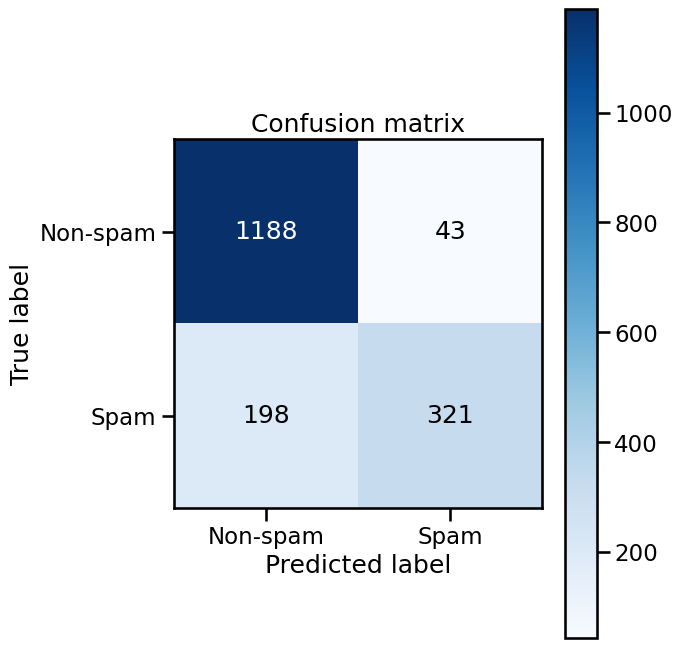

In [8]:
# Print classification report for test set
classification_report_(df_test, model)

# Print predictions on test set
plot_confusion_matrix(df_test, model)

### Approfondir la compréhension du modèle

Dans le cadre d'une régression logistique, les coefficients indiquent dans quelle mesure chaque caractéristique contribue à la prédiction globale. Plus la valeur absolue d'un coefficient est élevée, plus la caractéristique correspondante est importante pour le modèle.

Pour les caractéristiques numériques ainsi que pour celles issues de textes, les valeurs sont toujours positives. Par conséquent, les coefficients positifs favorisent la classe « spam », tandis que les coefficients négatifs favorisent la classe « non-spam ».

En ce qui concerne les caractéristiques issues de plongements (embeddings), les valeurs peuvent être aussi bien positives que négatives. Il est donc nécessaire d'examiner les contributions (le produit des valeurs des caractéristiques par leurs coefficients respectifs) pour évaluer leur impact sur la prédiction globale. Cette analyse permet de mieux comprendre le comportement du modèle et d'identifier les caractéristiques qui déterminent les prédictions pour des exemples donnés.

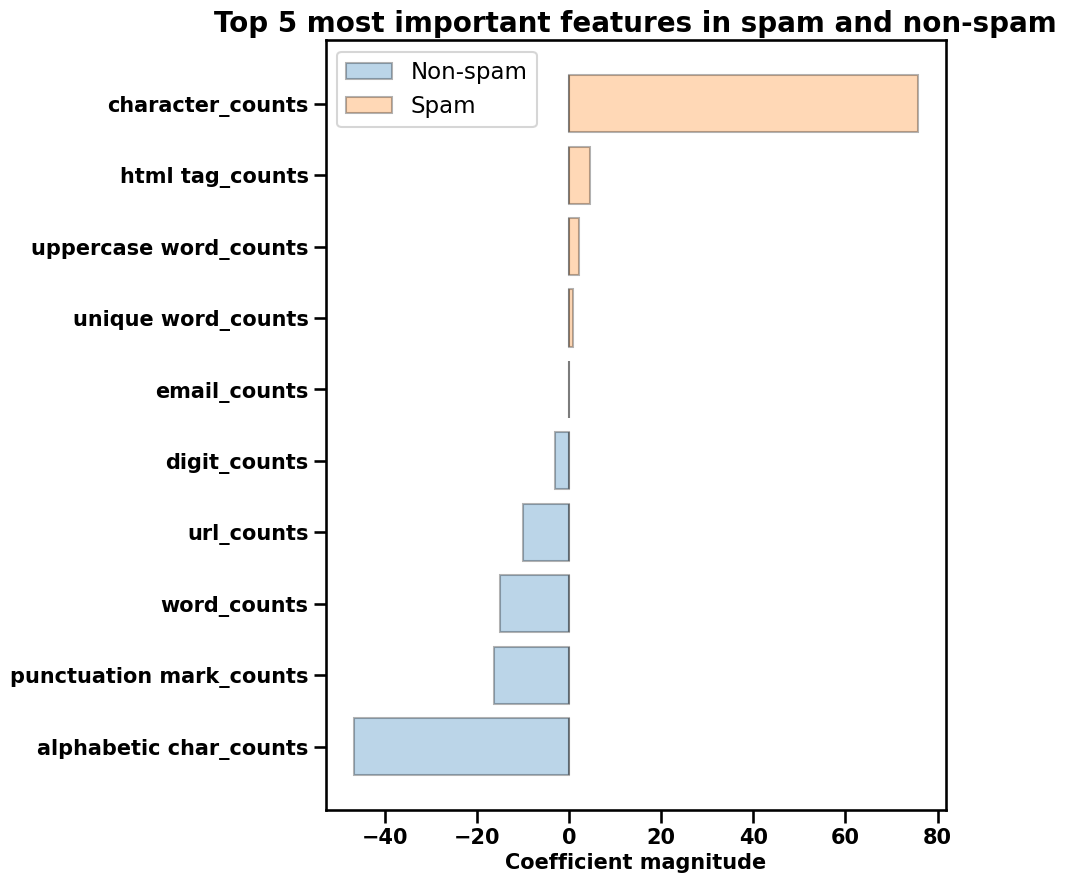

In [9]:
visualize_coefficients(model, df_train, n_top_features=5)

<div class="alert alert-success">


<h3>Questions</h3>

**Q1** Que nous indique le graphique ?


</div>

#### Indiquez ici votre observation :

**Q1**

- Un nombre élevé de caractères tend à orienter la prédiction vers du spam.
- Le nombre de caractères alphabétiques, la ponctuation et le nombre de mots jouent dans le sens inverse.

### Dans quelle mesure le modèle était-il confiant quant à ses prédictions ?

Le modèle de régression logistique peut renvoyer les probabilités associées à chaque classe pour chaque échantillon. Ces probabilités sont comprises entre 0 et 1, et leur somme pour chaque échantillon est égale à 1. Cela nous permet d'évaluer le degré de confiance du modèle dans ses prédictions.

Ci-dessous, nous représentons graphiquement les probabilités correspondant à la classe « spam », en utilisant des couleurs pour indiquer la classe réelle de chaque échantillon. Des probabilités faibles (proches de 0) indiquent que le modèle est très confiant dans le fait que l'échantillon n'est pas un spam, tandis que des probabilités élevées (proches de 1) indiquent qu'il est très confiant dans le fait qu'il s'agit bien d'un spam.

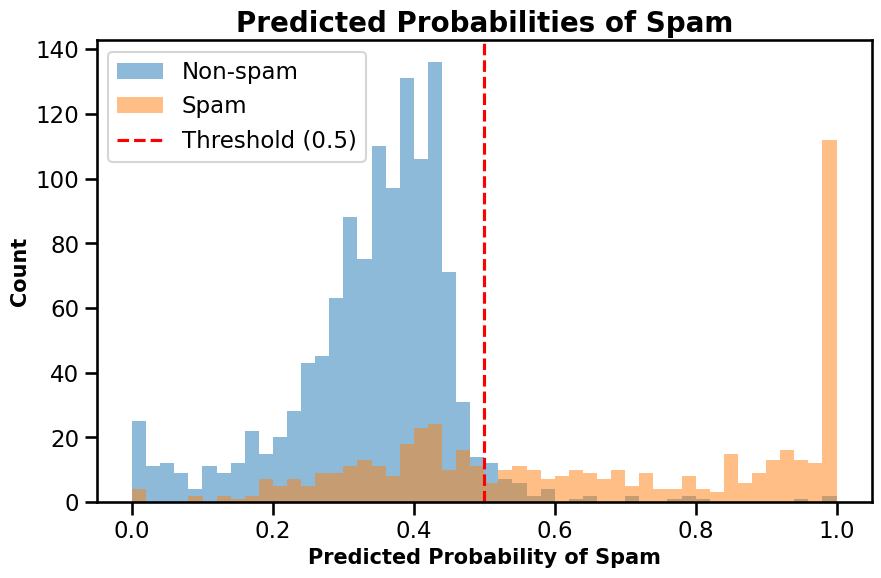

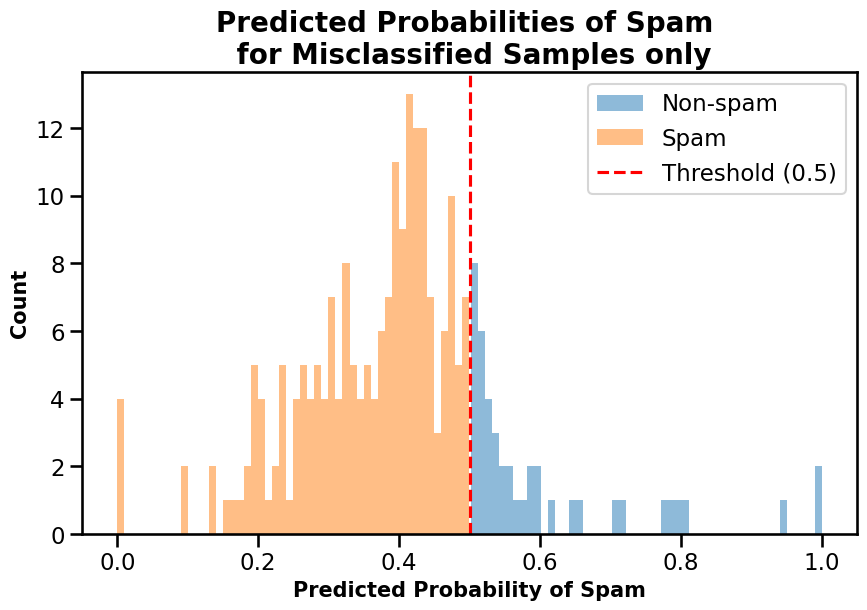

In [10]:
plot_prediction_certainties(df_test, model, log_scale=False)

<div class="alert alert-success">

<h3>Questions</h3>

Analysons les graphiques ci-dessus.

__Q1.__ Pour chaque classe, le modèle est-il « sûr » de ses prédictions ?

__Q2.__ Lorsqu'un échantillon est mal classé par le modèle, est-il généralement très sûr de sa prédiction ou plutôt incertain ?

Attention à l'interprétation : si le graphique du haut utilise `log-scale=True`, les valeurs ne sont pas uniformément espacées et cela peut induire en erreur. Vous pouvez modifier ce paramètre en utilisant `log-scale=False`.

</div>

#### Indiquez vos observations ici :


**Q1.**

- Il convient d'examiner le premier graphique.
- Sur les 519 courriels indésirables (spams), le modèle actuel affiche une « très grande certitude » pour 120 d'entre eux ; on observe ici une probabilité très élevée, proche de la perfection. Les autres probabilités sont réparties de manière quasi uniforme sur toute l'échelle.
- Pour les courriels légitimes (non-spams), le modèle actuel n'est pratiquement jamais sûr à 100 % qu'il ne s'agit pas de spams. Il leur attribue, pour la plupart, des probabilités comprises entre 25 % et 45 %. C'est suffisant pour aboutir à une classification correcte, mais cela ne témoigne pas d'une « certitude manifeste ».

**Q2.**

- Il convient d'examiner le deuxième graphique.
- Parmi les rares erreurs concernant les courriels légitimes, la plupart se situent juste du mauvais côté du seuil de décision.
- La majorité des erreurs portant sur les spams présentent, pour la catégorie « non-spam », des probabilités (entre 25 % et 45 %) identiques à celles attribuées aux courriels légitimes. Cela indique que le modèle actuel peine à distinguer ces spams des échantillons légitimes.

### Analyse des erreurs : où notre modèle fait-il défaut ?

Nous allons maintenant analyser les e-mails mal classés afin de mieux comprendre dans quels cas le modèle n'a pas réussi à effectuer des prédictions correctes. La fonction `error_analysis` ci-dessous nous permettra d'identifier les principaux facteurs ayant conduit le modèle à classer un e-mail comme spam ou non-spam.

In [11]:
%run modeling_tools.py

Coefficients: 13
Number of misclassified samples: 241

Overview for document index: 10

Original Text
On Saturday, September 21, 2002, at 10:59 PM, Joseph S. Barrera III wrote: > Better yet, tell me
where I should be listening for new music now that > P2P is dead and I still can't pick up KFJC very
well. KFJC has a MP3 stream at kfjc.org. I'd also recommend radioparadise.com. I remember the
Suburban Lawns, but I don't know what became of them. Apropos of nothing: "Spirited Away" is
amazing. Go see it now. -- whump 

Cleaned Text
saturday september joseph barrera wrote better tell listening music dead pick kfjc kfjc stream kfjc
recommend radioparadise remember suburban lawns dont know apropos spirited away amazing whump 


Predictions

Actual class:   Non-spam
Predicted class:   Spam

Predicted probabilities
Non-spam: 0.4729
Spam: 0.5271



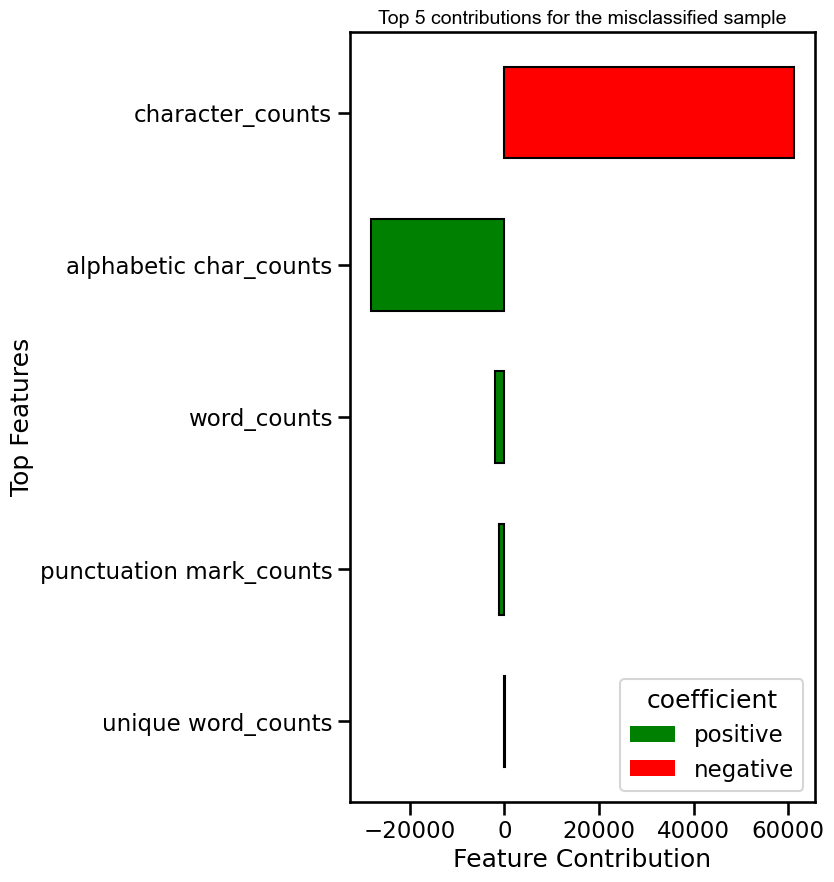

In [12]:
error_analysis(df_test, model, doc_nbr=10, n_top_coeff=5, color_by_coeff_sign=True)

<div class="alert alert-info">

# Votre terrain de jeu commence ici 😀
</div>

In [ ]:
# Load packages and helper functions
%run data_prep_tools.py
%run EDA_tools.py
%run modeling_tools.py

In [ ]:
# Load the data sets
num_features_df = load_feature_space("num", no_labels=False)
text_features_df = load_feature_space("text", no_labels=False)
num_text_features_df = load_feature_space("num_text", no_labels=False)
embedding_features = load_feature_space("embedding", no_labels=False)
labels = load_labels()

<div class="alert alert-success">
Nous avons reproduit ci-dessous les blocs de code présentés plus haut. Vous pouvez les utiliser pour concevoir votre propre détecteur de spams.

Plusieurs éléments peuvent être adaptés :

### Modifier l'espace des caractéristiques (feature space)

Nous avons défini 4 espaces de caractéristiques au début du notebook. Il vous suffit de remplacer `num_features_df` par `text_features`, `num_text_features` ou `embedding_features` dans le code ci-dessous pour utiliser un espace différent.

Attention : les espaces utilisant des caractéristiques textuelles sont assez lents ; l'exécution du réglage fin (fine-tuning) avec validation croisée prendra donc beaucoup de temps. Utilisez plutôt la fonction `fit_model` et faites varier directement le paramètre `C` (par exemple, `C=1`). (Certes, comme mentionné plus haut, ce n'est pas une bonne pratique, mais cela vous permet d'explorer le modèle.)

### Modifier la métrique utilisée pour le réglage fin

Vous pouvez modifier la fonction de score au sein de `fit_log_reg_model(df_train)`.

La valeur par défaut actuelle est `None`, ce qui signifie que le modèle utilise la fonction de score par défaut pour la régression logistique, à savoir l'exactitude (accuracy).

Vous pouvez toutefois choisir `"precision"`, `"recall"` ou `"f1"` pour observer l'évolution des résultats. D'autres options sont disponibles [ici](https://scikit-learn.org/stable/modules/model_evaluation.html#scoring-parameter).

Qu'advient-il de la matrice de confusion ?

### Explorer d'autres paramètres

Il sera probablement nécessaire d'ajuster certains paramètres, notamment ceux liés aux visualisations, afin de les rendre plus faciles à interpréter.

**Pour vous simplifier la tâche :**
**Nous avons regroupé tous les paramètres au même endroit ci-dessous.**

</div>

## Chargement des données

In [ ]:
# Change your settings here and then run the cell below, then come back and try again ;)

# Warning: Choosing text_features_df or num_text_features_df can take longer to run the full 5-fold cross-validation, so be patient

feature_space = num_features_df
C = 1
scoring = None

# For text features set `scaler=False`
scaler=True

## Construction du modèle

In [ ]:
# Train/test splitting
df_train, df_test = train_test_split_(feature_space)

# Fit model on the train data
model = fit_model(df_train, C=C)

# Print classification report for test set
classification_report_(df_test, model)

# Print predictions on test set
plot_confusion_matrix(df_test, model)

In [ ]:
%%time

# Train/test splitting
df_train, df_test = train_test_split_(feature_space)

# Fit model on the train data
model, cv_results = fit_log_reg_model(df_train, scoring=scoring, scaler=scaler)

In [ ]:
df_train.info()

### Suivi du surapprentissage

In [ ]:
viz_cv_results(cv_results, show_table=False, plot_confidence=False, plot_fit_time=False)

### Évaluation du modèle

In [ ]:
# Print classification report for test set
classification_report_(df_test, model)

# Print predictions on test set
plot_confusion_matrix(df_test, model)

### Approfondir la compréhension du modèle

In [ ]:
%run modeling_tools.py

visualize_coefficients(model, df_train, n_top_features=5)

### Dans quelle mesure le modèle était-il confiant quant à ses prédictions ?


In [ ]:
plot_prediction_certainties(df_test, model, log_scale=False)

<div class="alert alert-success">


<h3>Questions</h3>

Let's explore the plot above. 

__Q1.__ When the model misclassified a sample, is it usually very sure of its prediction, or kind of doubtful?

Careful with interpretation when the top plot using a log-scale. This means that the values are not evenly spaced. You can change the setting.

</div>

#### Give your observation here:

1.    















### Analyse des erreurs : où notre modèle fait-il défaut ?

In [ ]:
error_analysis(df_test, model, doc_nbr=10, n_top_coeff=5, color_by_coeff_sign=True)

<div class="alert alert-info">

# Votre terrain de jeu s'arrête ici ☹️

# Mais vous pouvez remonter et recommencer 😀

</div>